In [1]:
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ConvLSTM2D, Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

In [2]:
df = pd.read_csv("forex_usd_inr_2007_to_present.csv")
# Remove 2nd and 3rd rows (Python uses zero-based indexing)
df = df.drop([1, 2]).reset_index(drop=True)

# Optional: verify
print(df.head(5))


        Price               Close                High                 Low  \
0      Ticker            USDINR=X            USDINR=X            USDINR=X   
1  2007-01-02   44.12200164794922  44.220001220703125   44.07500076293945   
2  2007-01-03  44.111000061035156   44.40999984741211   44.08599853515625   
3  2007-01-04  44.095001220703125   44.47999954223633  44.095001220703125   
4  2007-01-05   44.13999938964844   44.33000183105469  44.095001220703125   

                 Open    Volume  
0            USDINR=X  USDINR=X  
1   44.21200180053711         0  
2  44.119998931884766         0  
3  44.119998931884766         0  
4  44.095001220703125         0  


In [3]:
# Assuming your DataFrame is named df
df = df.drop(index=0).reset_index(drop=True)

# Optional: confirm it worked
print(df.head())


        Price               Close                High                 Low  \
0  2007-01-02   44.12200164794922  44.220001220703125   44.07500076293945   
1  2007-01-03  44.111000061035156   44.40999984741211   44.08599853515625   
2  2007-01-04  44.095001220703125   44.47999954223633  44.095001220703125   
3  2007-01-05   44.13999938964844   44.33000183105469  44.095001220703125   
4  2007-01-08  44.255001068115234                44.5  44.255001068115234   

                 Open Volume  
0   44.21200180053711      0  
1  44.119998931884766      0  
2  44.119998931884766      0  
3  44.095001220703125      0  
4    44.3650016784668      0  


In [4]:
df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']  # rename manually

In [5]:
for col in df.columns:
    if col != 'Date':
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Optional: fill missing values created by coercion
df = df.fillna(method='ffill').fillna(method='bfill')

# Confirm that everything is now numeric
print(df.dtypes)

Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


C:\Users\ASUS\AppData\Local\Temp\ipykernel_20268\1277827392.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill').fillna(method='bfill')


Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


275/275 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 1089.1539 - val_loss: 16.4868
Epoch 2/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 23.4902 - val_loss: 5.9859
Epoch 3/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 13.1382 - val_loss: 9.2209
Epoch 4/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 9.2154 - val_loss: 13.9364
Epoch 5/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 6.6712 - val_loss: 14.3617
Epoch 6/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5.8543 - val_loss: 10.8090
Epoch 7/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 4.8905 - val_loss: 16.6608
Epoch 8/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 3.9107 - val_loss: 14.0670
Epoch 9/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 3.2722 - val_loss: 27.2037
Epoch 10/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.9146 - val_loss: 17.8519
Epoch 11/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 2.6193 - val_loss: 27.8393
Epoch 12/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/s

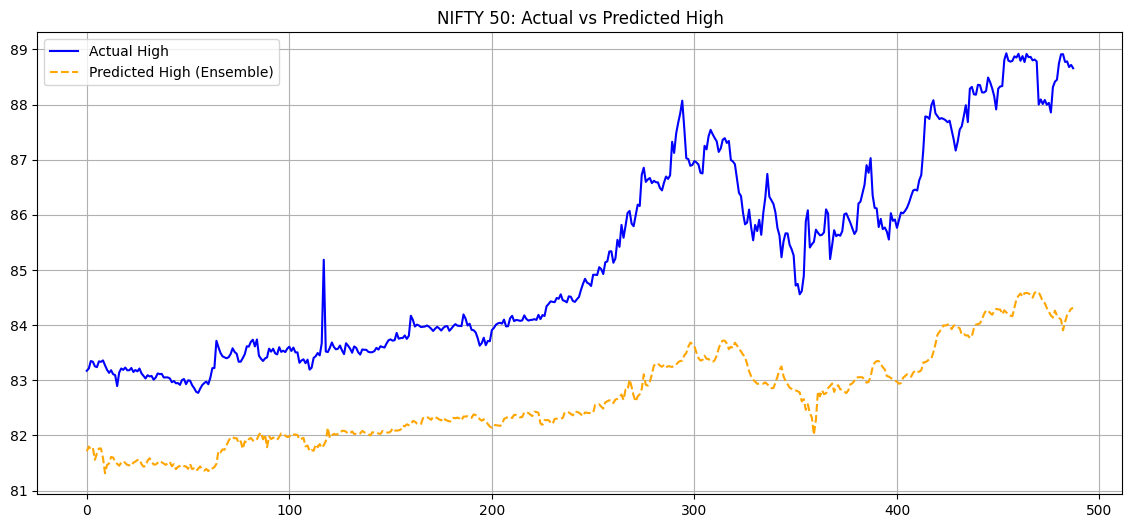

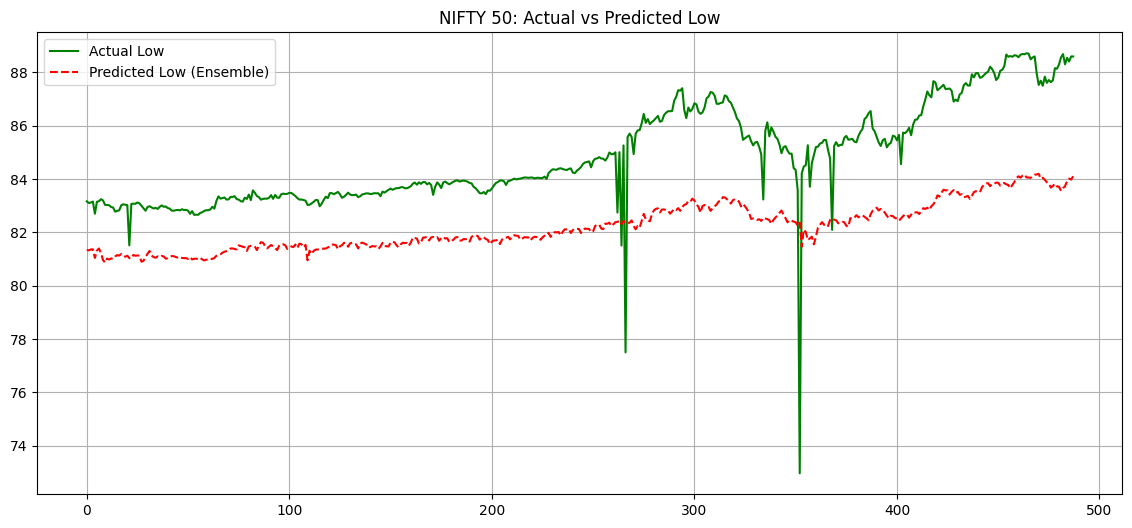

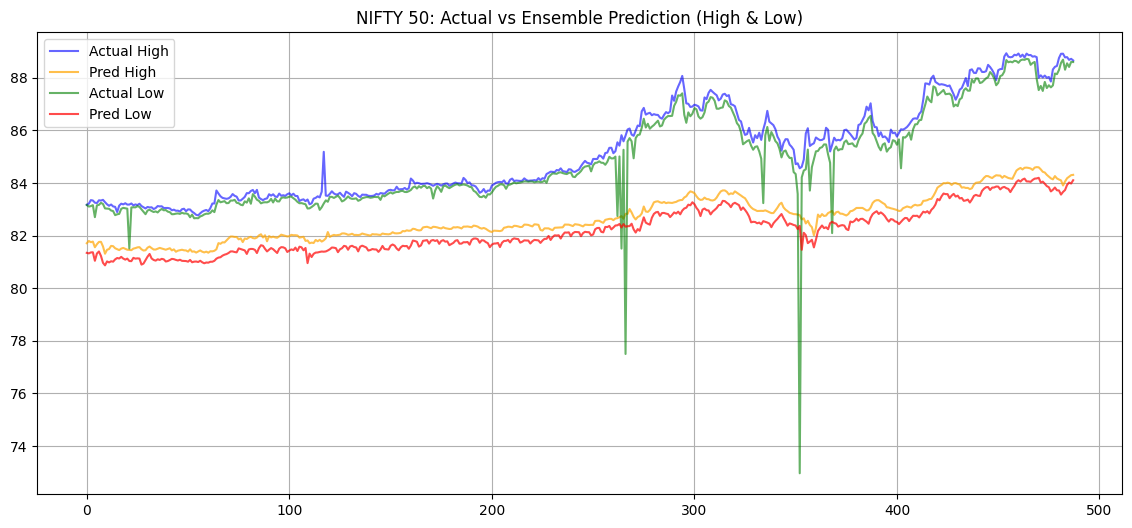

In [7]:
df['Date'] = pd.to_datetime(df['Date'])
df = df.sort_values('Date').reset_index(drop=True)

# Create lag features
for lag in range(1, 6):
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'High_lag_{lag}'] = df['High'].shift(lag)
    df[f'Low_lag_{lag}'] = df['Low'].shift(lag)

# Rolling mean and std
df['MA_5'] = df['Close'].rolling(window=5).mean()
df['STD_5'] = df['Close'].rolling(window=5).std()

# Date-time features
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['Month'] = df['Date'].dt.month

# Drop NaN
df = df.dropna().reset_index(drop=True)

# ------------------------------------------------------------
# STEP 2: DEFINE FEATURES & TARGETS
# ------------------------------------------------------------
features = [col for col in df.columns if col not in ['Date', 'High', 'Low']]
X = df[features]
y_high = df['High']
y_low = df['Low']

# Train-Test Split (no shuffle, to preserve time order)
split_ratio = 0.9
split_idx = int(len(df) * split_ratio)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_high_train, y_high_test = y_high.iloc[:split_idx], y_high.iloc[split_idx:]
y_low_train, y_low_test = y_low.iloc[:split_idx], y_low.iloc[split_idx:]

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# STEP 3: XGBOOST MODELS (TABULAR)
# ------------------------------------------------------------
xgb_high = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)
xgb_low = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)

xgb_high.fit(X_train_scaled, y_high_train)
xgb_low.fit(X_train_scaled, y_low_train)

pred_high_xgb = xgb_high.predict(X_test_scaled)
pred_low_xgb = xgb_low.predict(X_test_scaled)

# ------------------------------------------------------------
# STEP 4: ConvLSTM MODEL (SEQUENTIAL)
# ------------------------------------------------------------
def create_sequences(X, y_high, y_low, seq_len=5):
    X_seq, yh_seq, yl_seq = [], [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        yh_seq.append(y_high[i])
        yl_seq.append(y_low[i])
    return np.array(X_seq), np.array(yh_seq), np.array(yl_seq)

seq_len = 5
X_scaled_full = scaler.fit_transform(X)
X_seq, y_high_seq, y_low_seq = create_sequences(X_scaled_full, y_high.values, y_low.values, seq_len)

split_idx_seq = int(len(X_seq) * split_ratio)
X_train_seq, X_test_seq = X_seq[:split_idx_seq], X_seq[split_idx_seq:]
y_high_train_seq, y_high_test_seq = y_high_seq[:split_idx_seq], y_high_seq[split_idx_seq:]
y_low_train_seq, y_low_test_seq = y_low_seq[:split_idx_seq], y_low_seq[split_idx_seq:]

# Reshape for ConvLSTM: [samples, timesteps, rows, cols, features]
X_train_seq = X_train_seq.reshape((X_train_seq.shape[0], seq_len, 1, 1, X_train_seq.shape[2]))
X_test_seq = X_test_seq.reshape((X_test_seq.shape[0], seq_len, 1, 1, X_test_seq.shape[2]))

model = Sequential([
    ConvLSTM2D(32, (1,1), activation='relu', input_shape=(seq_len, 1, 1, X_train_seq.shape[-1]), return_sequences=True),
    Dropout(0.2),
    ConvLSTM2D(16, (1,1), activation='relu'),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(2)
])
model.compile(optimizer=Adam(0.001), loss='mse')

y_train_seq_combined = np.column_stack((y_high_train_seq, y_low_train_seq))
y_test_seq_combined = np.column_stack((y_high_test_seq, y_low_test_seq))

history = model.fit(
    X_train_seq, y_train_seq_combined,
    epochs=25, batch_size=16, validation_data=(X_test_seq, y_test_seq_combined),
    verbose=1
)

pred_seq = model.predict(X_test_seq)
pred_high_conv, pred_low_conv = pred_seq[:,0], pred_seq[:,1]

# ------------------------------------------------------------
# STEP 5: ENSEMBLE (WEIGHTED AVERAGE)
# ------------------------------------------------------------
# Align sequence-based test predictions with tabular test indices
min_len = min(len(pred_high_conv), len(pred_high_xgb))
pred_high_ensemble = 0.6 * pred_high_conv[-min_len:] + 0.4 * pred_high_xgb[-min_len:]
pred_low_ensemble  = 0.6 * pred_low_conv[-min_len:]  + 0.4 * pred_low_xgb[-min_len:]

y_high_true = y_high_test.values[-min_len:]
y_low_true = y_low_test.values[-min_len:]

# ------------------------------------------------------------
# STEP 6: METRICS
# ------------------------------------------------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

m_high = metrics(y_high_true, pred_high_ensemble, "High (Ensemble)")
m_low = metrics(y_low_true, pred_low_ensemble, "Low (Ensemble)")

# ------------------------------------------------------------
# STEP 7: VISUAL COMPARISONS
# ------------------------------------------------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High", color='blue')
plt.plot(pred_high_ensemble, label="Predicted High (Ensemble)", color='orange', linestyle='--')
plt.title("NIFTY 50: Actual vs Predicted High")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low_ensemble, label="Predicted Low (Ensemble)", color='red', linestyle='--')
plt.title("NIFTY 50: Actual vs Predicted Low")
plt.legend()
plt.grid(True)
plt.show()

# Optional: plot combined
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High", color='blue', alpha=0.6)
plt.plot(pred_high_ensemble, label="Pred High", color='orange', alpha=0.7)
plt.plot(y_low_true, label="Actual Low", color='green', alpha=0.6)
plt.plot(pred_low_ensemble, label="Pred Low", color='red', alpha=0.7)
plt.title("NIFTY 50: Actual vs Ensemble Prediction (High & Low)")
plt.legend()
plt.grid(True)
plt.show()


📊 High (XGBoost) Metrics:
MAE  : 1.868
RMSE : 2.565
R²   : -0.995
MAPE : 2.15%

📊 Low (XGBoost) Metrics:
MAE  : 1.800
RMSE : 2.477
R²   : -0.758
MAPE : 2.09%


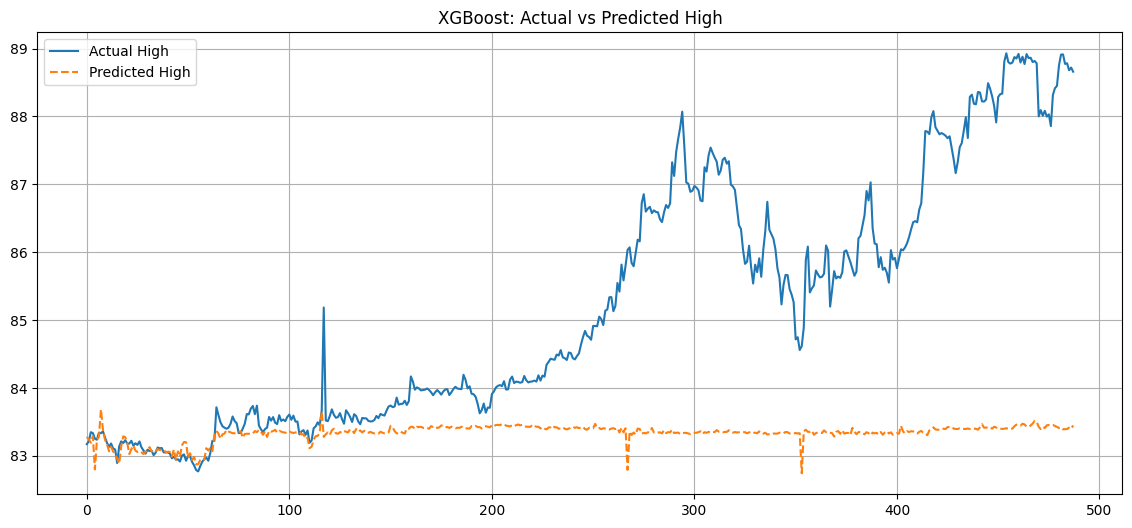

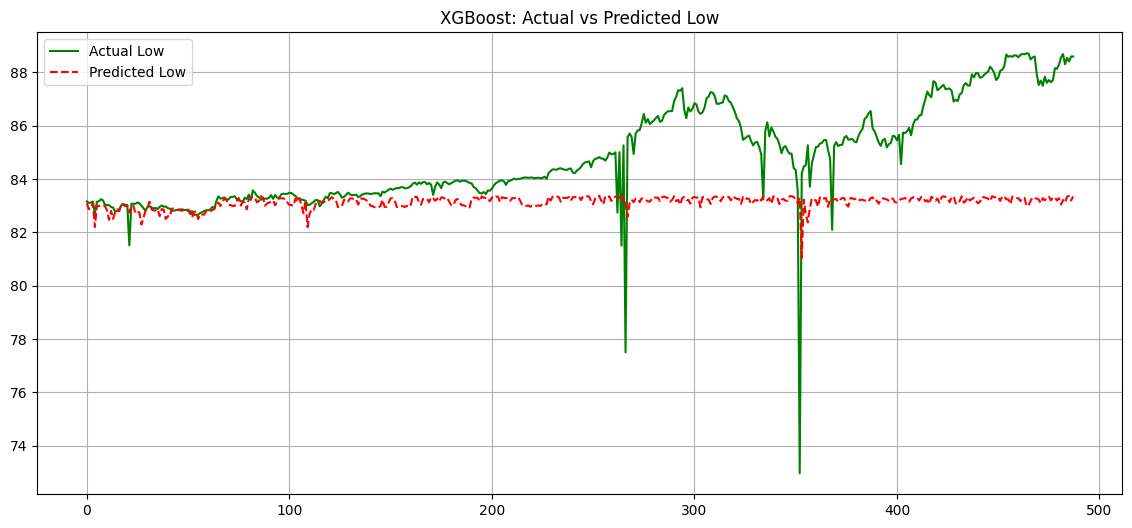

In [8]:
for lag in range(1,6):
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'High_lag_{lag}'] = df['High'].shift(lag)
    df[f'Low_lag_{lag}'] = df['Low'].shift(lag)

# Drop NaNs
df = df.dropna().reset_index(drop=True)

# Features & target
features = [col for col in df.columns if col not in ['Date', 'High', 'Low']]
X = df[features]
y_high = df['High']
y_low = df['Low']

# Train-test split (no shuffle)
split_idx = int(len(df)*0.9)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_high_train, y_high_test = y_high.iloc[:split_idx], y_high.iloc[split_idx:]
y_low_train, y_low_test = y_low.iloc[:split_idx], y_low.iloc[split_idx:]

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------ TRAIN XGBOOST ------------------
xgb_high = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)
xgb_low = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)

xgb_high.fit(X_train_scaled, y_high_train)
xgb_low.fit(X_train_scaled, y_low_train)

# Predict
pred_high = xgb_high.predict(X_test_scaled)
pred_low = xgb_low.predict(X_test_scaled)

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_test, pred_high, "High (XGBoost)")
metrics(y_low_test, pred_low, "Low (XGBoost)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_test.values, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("XGBoost: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_test.values, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("XGBoost: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [9]:
from tensorflow.keras.layers import LSTM, Dense, Dropout

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0486 - val_loss: 0.0300
Epoch 2/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0202 - val_loss: 0.0045
Epoch 3/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0176 - val_loss: 0.0072
Epoch 4/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0159 - val_loss: 0.0019
Epoch 5/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0152 - val_loss: 0.0022
Epoch 6/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0147 - val_loss: 0.0020
Epoch 7/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0144 - val_loss: 0.0048
Epoch 8/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0143 - val_loss: 0.0031
Epoch 9/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0140 - val_loss: 0.0017
Epoch 10/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0140 - val_loss: 0.0034
Epoch 11/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0145 - val_loss: 0.0022
Epoch 12/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.

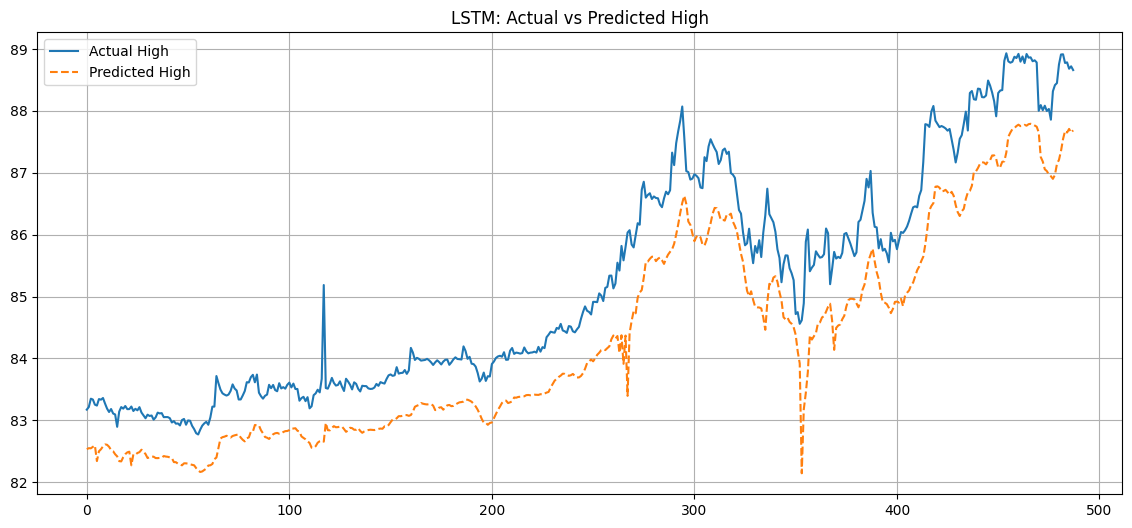

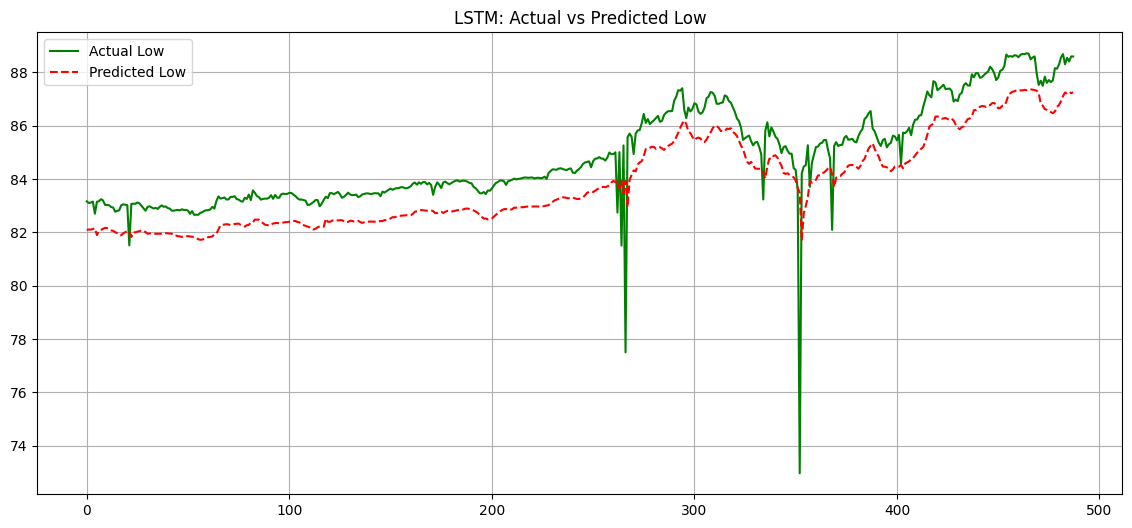

In [10]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(X_train, y_train, epochs=25, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [11]:
from sklearn.preprocessing import MinMaxScaler

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.2112 - val_loss: 0.0332
Epoch 2/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0215 - val_loss: 0.0026
Epoch 3/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0184 - val_loss: 0.0038
Epoch 4/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0165 - val_loss: 0.0040
Epoch 5/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0163 - val_loss: 0.0189
Epoch 6/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0162 - val_loss: 0.0149
Epoch 7/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0150 - val_loss: 0.0033
Epoch 8/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0151 - val_loss: 0.0087
Epoch 9/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0153 - val_loss: 0.0056
Epoch 10/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0151 - val_loss: 0.0129
Epoch 11/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0156 - val_loss: 0.0118
Epoch 12/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.

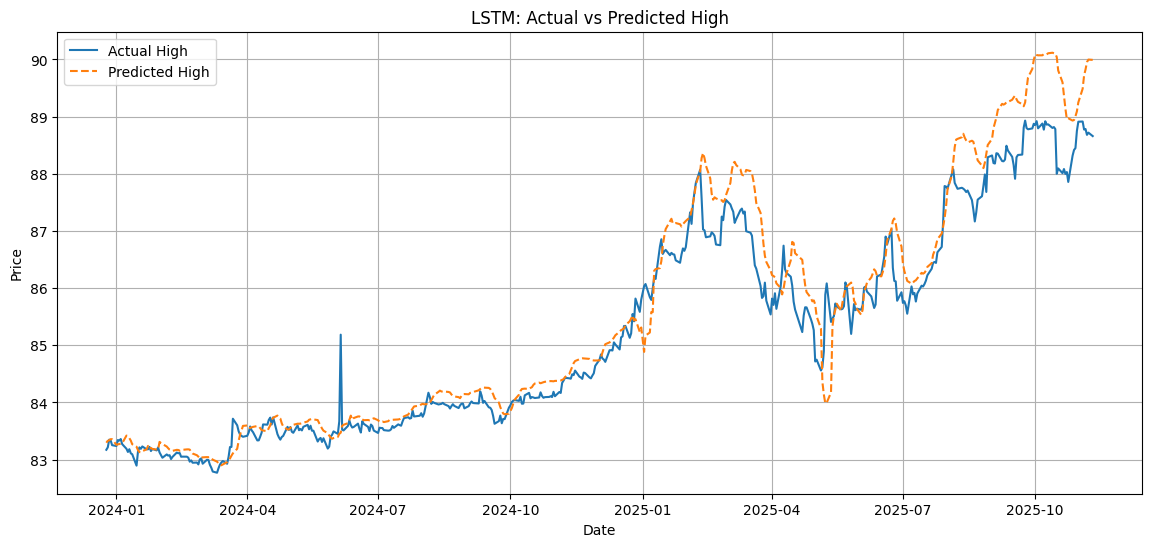

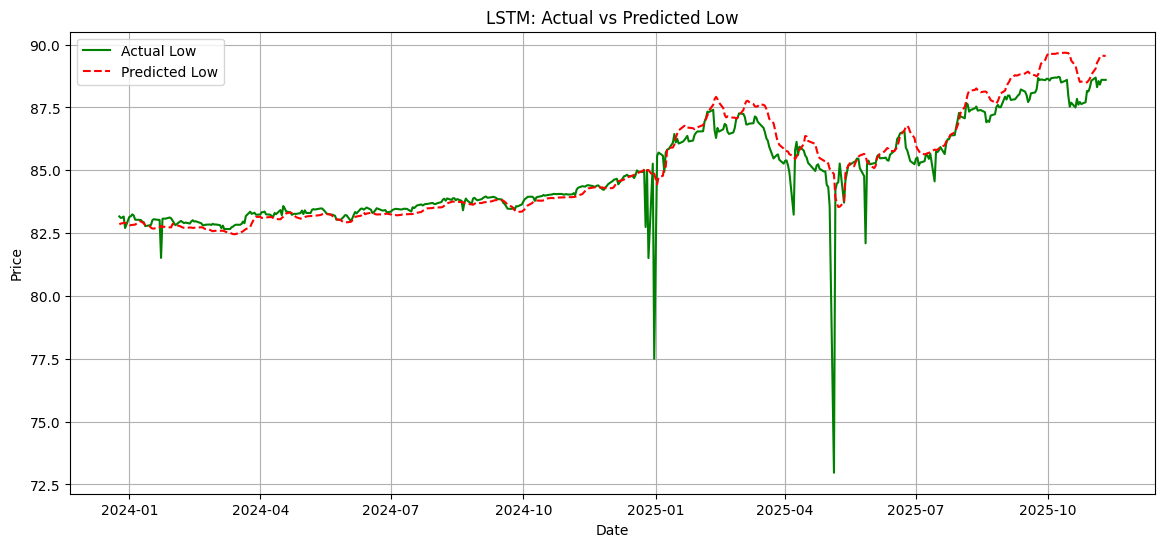

In [12]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# Corresponding dates for test set
test_dates = df['Date'].values[seq_len + split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(
    X_train, y_train,
    epochs=25, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_high_true, label="Actual High")
plt.plot(test_dates, pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(test_dates, y_low_true, label="Actual Low", color='green')
plt.plot(test_dates, pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1289 - val_loss: 0.0029
Epoch 2/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0258 - val_loss: 0.0033
Epoch 3/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0225 - val_loss: 0.0154
Epoch 4/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0206 - val_loss: 0.0048
Epoch 5/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0199 - val_loss: 0.0016
Epoch 6/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0193 - val_loss: 0.0034
Epoch 7/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0178 - val_loss: 0.0510
Epoch 8/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0169 - val_loss: 0.0016
Epoch 9/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0168 - val_loss: 0.0025
Epoch 10/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0170 - val_loss: 0.0135
Epoch 11/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0164 - val_loss: 0.0025
Epoch 12/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.

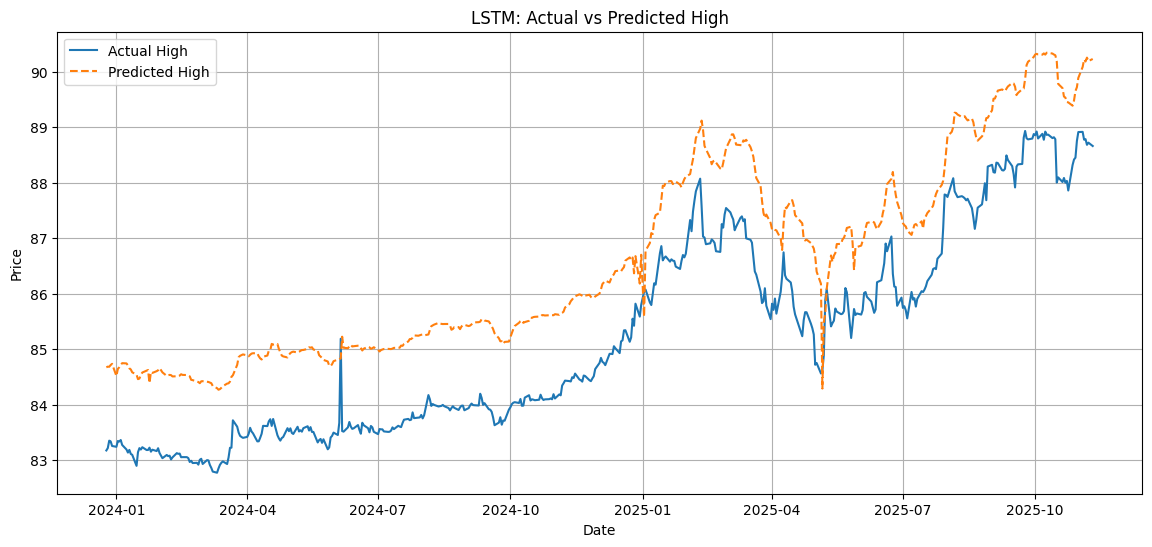

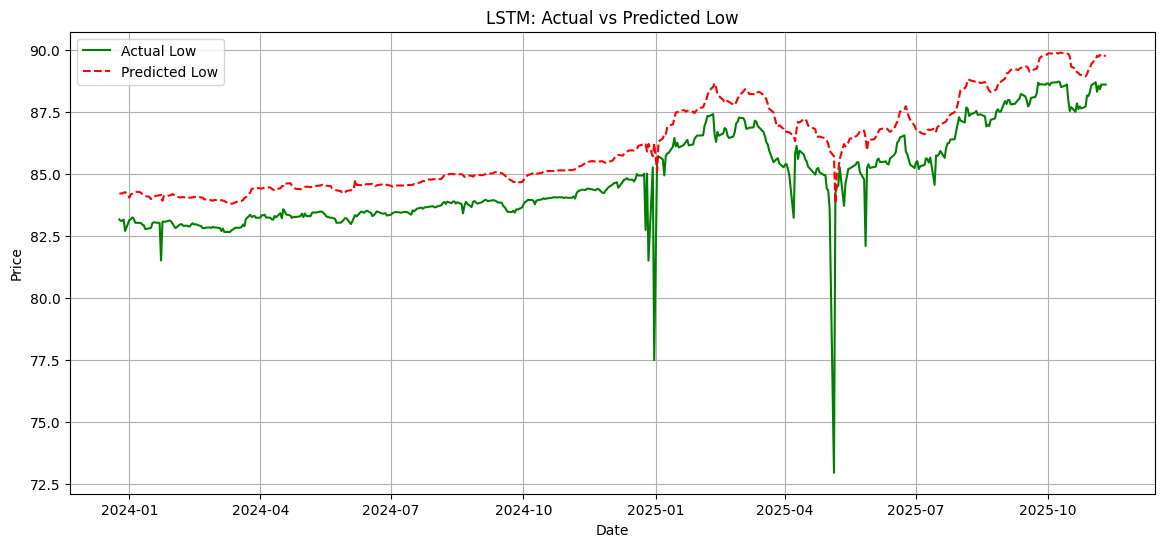

In [13]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# Corresponding dates for test set
test_dates = df['Date'].values[seq_len + split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(
    X_train, y_train,
    epochs=25, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_high_true, label="Actual High")
plt.plot(test_dates, pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(test_dates, y_low_true, label="Actual Low", color='green')
plt.plot(test_dates, pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0899 - val_loss: 0.0051
Epoch 2/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0213 - val_loss: 0.0076
Epoch 3/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0181 - val_loss: 0.0023
Epoch 4/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0168 - val_loss: 0.0019
Epoch 5/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0158 - val_loss: 0.0130
Epoch 6/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0154 - val_loss: 0.0016
Epoch 7/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0149 - val_loss: 0.0027
Epoch 8/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0135 - val_loss: 0.0017
Epoch 9/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0129 - val_loss: 0.0030
Epoch 10/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0140 - val_loss: 0.0034
Epoch 11/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0132 - val_loss: 0.0016
Epoch 12/25
275/275 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.

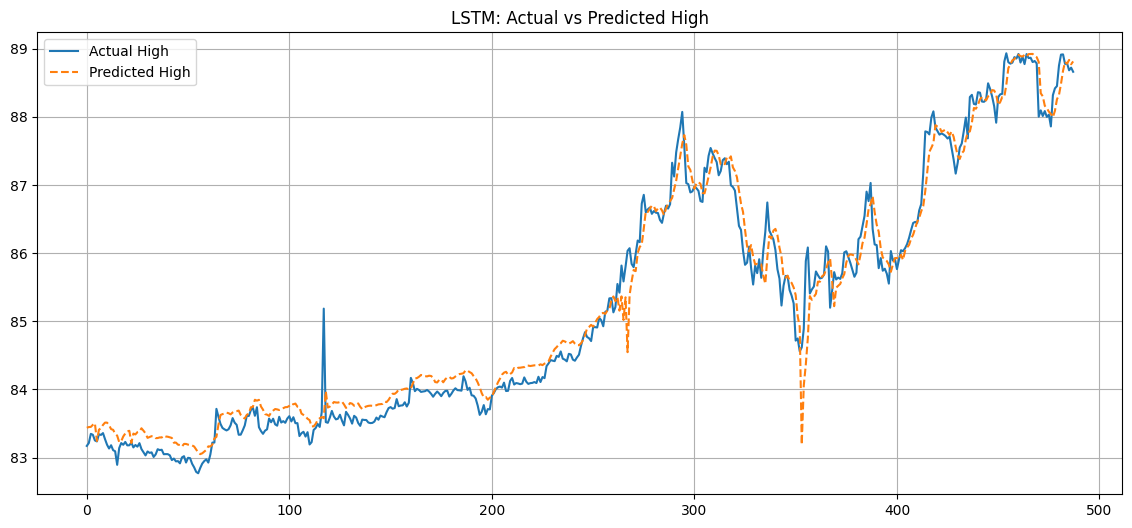

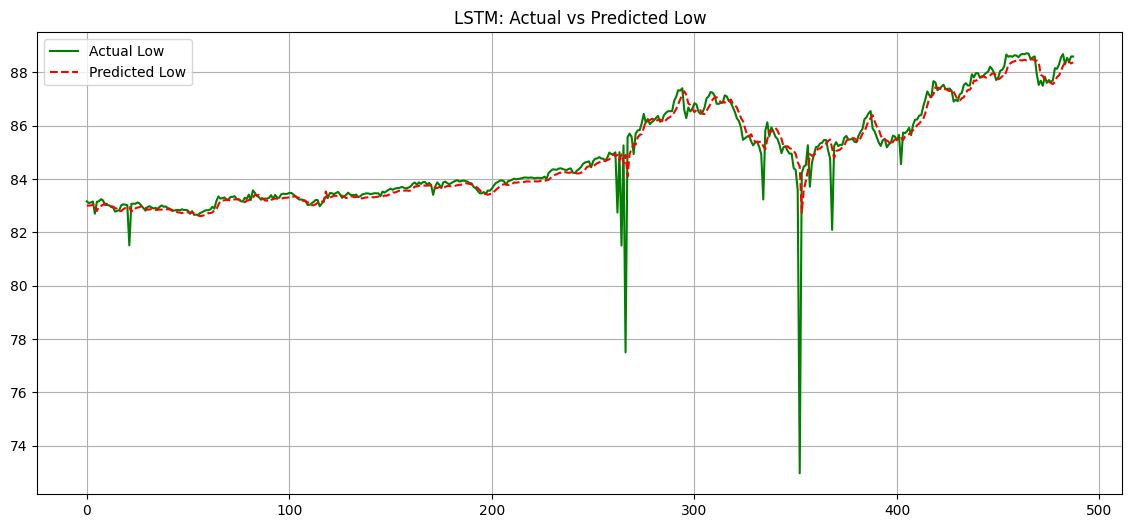

In [14]:
#for sequence length 50
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(X_train, y_train, epochs=25, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [15]:
from tcn import TCN

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tcn (TCN)                       │ (None, 64)             │        87,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 50)             │         3,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,968 (355.34 KB)

 Trainable params: 90,968 (355.34 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 1.8863 - val_loss: 0.1358
Epoch 2/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1609 - val_loss: 0.1566
Epoch 3/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.1085 - val_loss: 0.1099
Epoch 4/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0766 - val_loss: 0.0497
Epoch 5/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0621 - val_loss: 0.0111
Epoch 6/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0530 - val_loss: 0.0470
Epoch 7/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0482 - val_loss: 0.0874
Epoch 8/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0442 - val_loss: 0.0611
Epoch 9/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0414 - val_loss: 0.0288
Epoch 10/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0360 - val_loss: 0.0203
Epoch 11/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0347 - val_loss: 0.0139
Epoch 12/30
272/272 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step

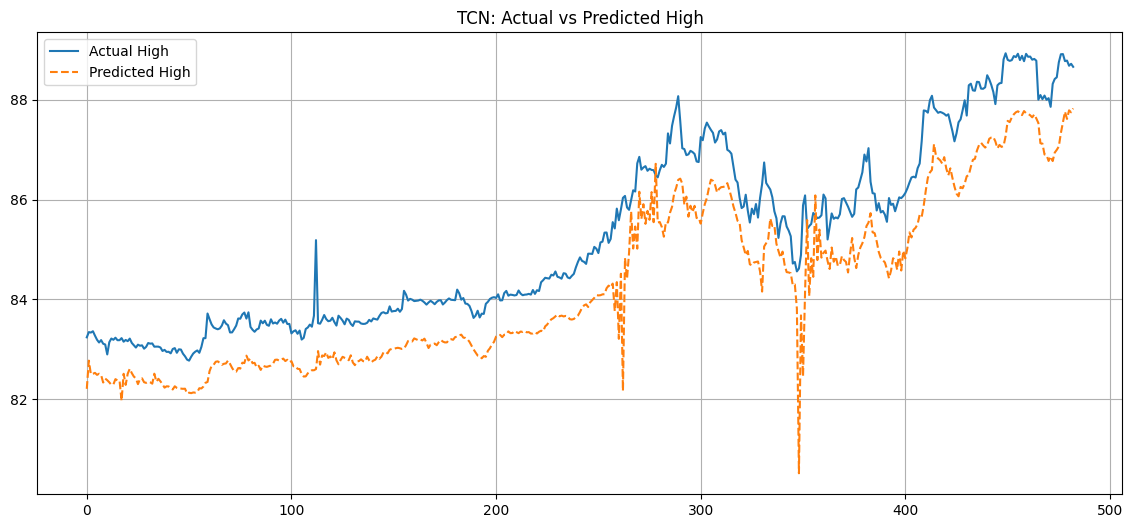

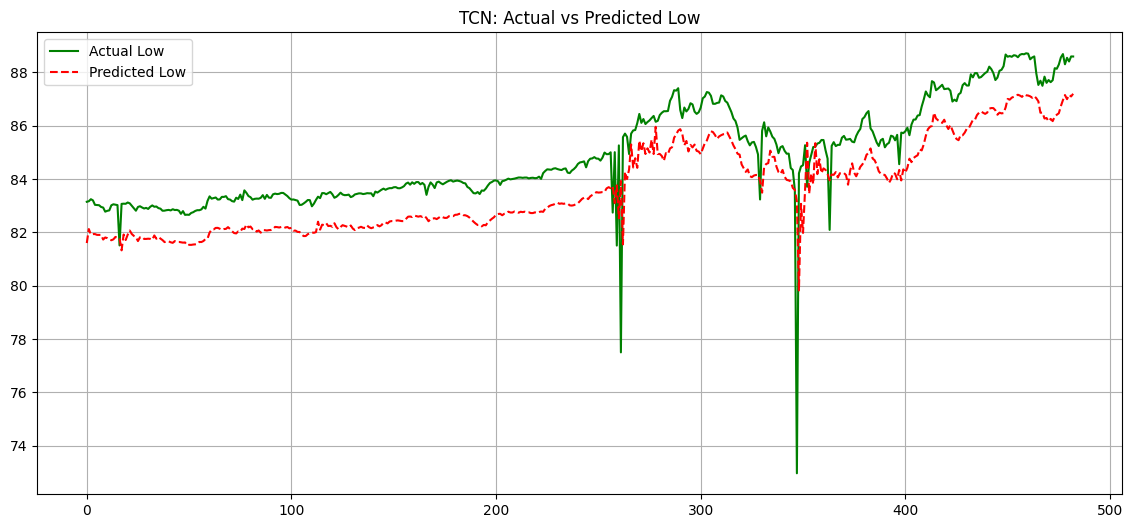

In [16]:





features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y = df[['High','Low']].values

# ------------------ SCALING ------------------
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

# ------------------ CREATE SEQUENCES ------------------
def create_sequences(X, y, seq_len=50):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 50  # Hyperparameter: sequence length
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ BUILD TCN MODEL ------------------
model = Sequential([
    TCN(input_shape=(seq_len, X_train.shape[2]), 
        nb_filters=64,       # Number of convolutional filters
        kernel_size=3,       # Filter/kernel size
        dilations=[1,2,4,8],# Dilation factors for receptive field
        dropout_rate=0.2,    # Dropout for regularization
        return_sequences=False),
    Dense(50, activation='relu'),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# ------------------ TRAIN ------------------
history = model.fit(
    X_train, y_train,
    epochs=30, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_inv = scaler_y.inverse_transform(y_test)

y_high_pred, y_low_pred = y_pred[:,0], y_pred[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, y_high_pred, "High (TCN)")
metrics(y_low_true, y_low_pred, "Low (TCN)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(y_high_pred, label="Predicted High", linestyle='--')
plt.title("TCN: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(y_low_pred, label="Predicted Low", linestyle='--', color='red')
plt.title("TCN: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()


In [17]:
from sklearn.preprocessing import MinMaxScaler

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tcn_1 (TCN)                     │ (None, 128)            │       464,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 472,642 (1.80 MB)

 Trainable params: 472,642 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - loss: 3.5371 - val_loss: 0.0199
Epoch 2/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0455 - val_loss: 0.0203
Epoch 3/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0296 - val_loss: 0.0096
Epoch 4/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0214 - val_loss: 0.0099
Epoch 5/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0176 - val_loss: 0.0043
Epoch 6/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0146 - val_loss: 0.0069
Epoch 7/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0127 - val_loss: 0.0050
Epoch 8/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0119 - val_loss: 0.0048
Epoch 9/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.0104 - val_loss: 0.0043
Epoch 10/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0101 - val_loss: 0.0025
Epoch 11/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 3s 19ms/step - loss: 0.0092 - val_loss: 0.0046
Epoch 12/50
136/136 ━━━━━━━━━━━━━━━━━━━━ 

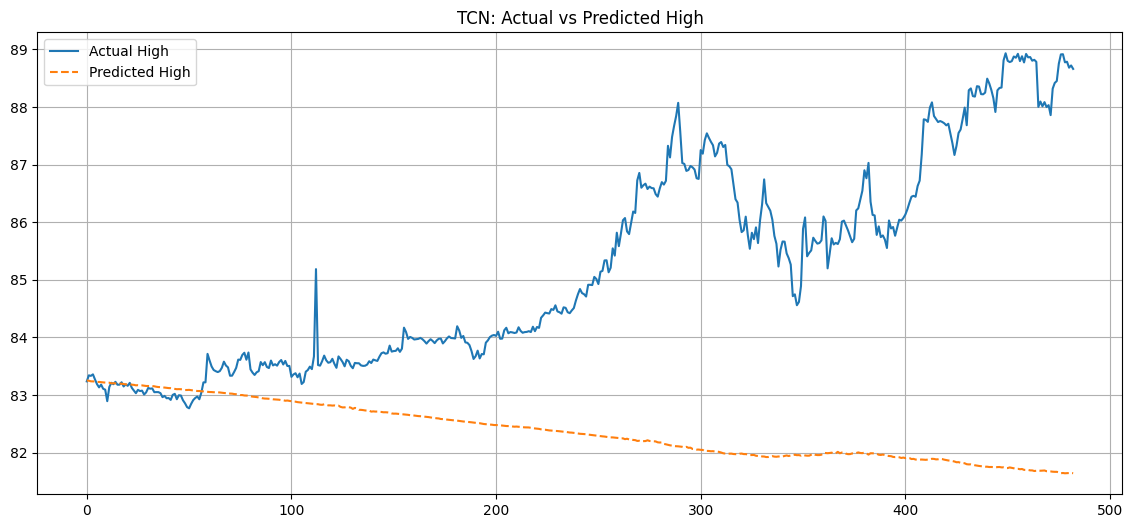

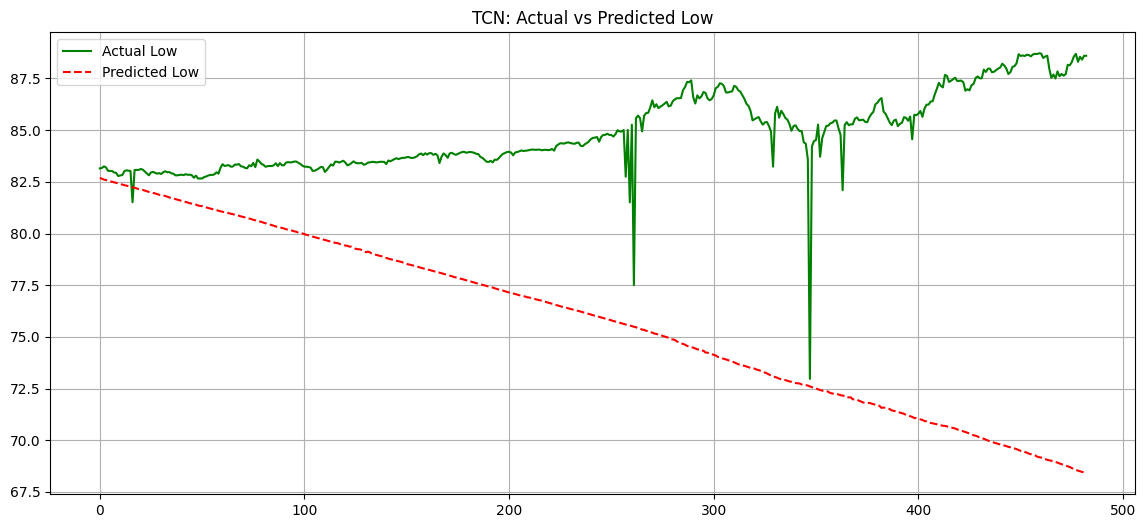

In [18]:


# Create percentage change features (returns)
df['Open_ret'] = df['Open'].pct_change()
df['High_ret'] = df['High'].pct_change()
df['Low_ret'] = df['Low'].pct_change()
df['Close_ret'] = df['Close'].pct_change()

# Drop first row (NaN due to pct_change)
df = df.dropna().reset_index(drop=True)

# Create lag features
lags = 5
for col in ['Open_ret','High_ret','Low_ret','Close_ret']:
    for lag in range(1, lags+1):
        df[f'{col}_lag{lag}'] = df[col].shift(lag)

df = df.dropna().reset_index(drop=True)

# Define features and targets
features = [c for c in df.columns if 'lag' in c]
X = df[features].values
y = df[['High_ret','Low_ret']].values  # Predict next-day returns

# ------------------ SCALING ------------------
scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y)

# ------------------ CREATE SEQUENCES ------------------
def create_sequences(X, y, seq_len=50):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 50
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ BUILD TCN MODEL ------------------
model = Sequential([
    TCN(input_shape=(seq_len, X_train.shape[2]), 
        nb_filters=128,
        kernel_size=3,
        dilations=[1,2,4,8,16],
        dropout_rate=0.2,
        return_sequences=False),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(2)  # Predict High & Low returns
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# ------------------ TRAIN ------------------
history = model.fit(
    X_train, y_train,
    epochs=50, batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_inv = scaler_y.inverse_transform(y_test)

# Convert predicted returns back to price
last_high = df['High'].values[split_idx + seq_len - 1]
last_low = df['Low'].values[split_idx + seq_len - 1]

y_high_pred_prices = [last_high*(1 + y_pred[0,0])]
y_low_pred_prices  = [last_low*(1 + y_pred[0,1])]

for i in range(1, len(y_pred)):
    y_high_pred_prices.append(y_high_pred_prices[-1]*(1 + y_pred[i,0]))
    y_low_pred_prices.append(y_low_pred_prices[-1]*(1 + y_pred[i,1]))

y_high_true_prices = df['High'].values[split_idx + seq_len:]
y_low_true_prices  = df['Low'].values[split_idx + seq_len:]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true_prices, y_high_pred_prices, "High (TCN)")
metrics(y_low_true_prices, y_low_pred_prices, "Low (TCN)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true_prices, label="Actual High")
plt.plot(y_high_pred_prices, label="Predicted High", linestyle='--')
plt.title("TCN: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true_prices, label="Actual Low", color='green')
plt.plot(y_low_pred_prices, label="Predicted Low", linestyle='--', color='red')
plt.title("TCN: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()
